# U.S. Hospital Quality — Python Visualization

This notebook translates selected findings from the SQL analysis into
portfolio-ready visualizations.

The goal is not to reproduce every SQL result, but to visualize findings
where graphical presentation improves interpretation.


In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully")

Matplotlib imported successfully


## 1. Distribution of Overall Hospital Ratings

**Question:** Among hospitals with a numeric overall hospital rating,
how are ratings distributed from 1 to 5 stars?

Only hospitals with valid numeric ratings are included. Hospitals without
a reported overall rating are excluded from this visualization.

In [3]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("../data/hospital_quality.db")
FIGURE_DIR = Path("../outputs/figures")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect(DB_PATH)

In [4]:
rating_query = """
SELECT
    overall_rating,
    COUNT(*) AS hospital_count
FROM hospitals
WHERE overall_rating IN ('1', '2', '3', '4', '5')
GROUP BY overall_rating
ORDER BY CAST(overall_rating AS INTEGER);
"""

rating_counts = pd.read_sql_query(rating_query, conn)

rating_counts

,overall_rating,hospital_count
0,1,198
1,2,661
2,3,985
3,4,946
4,5,384


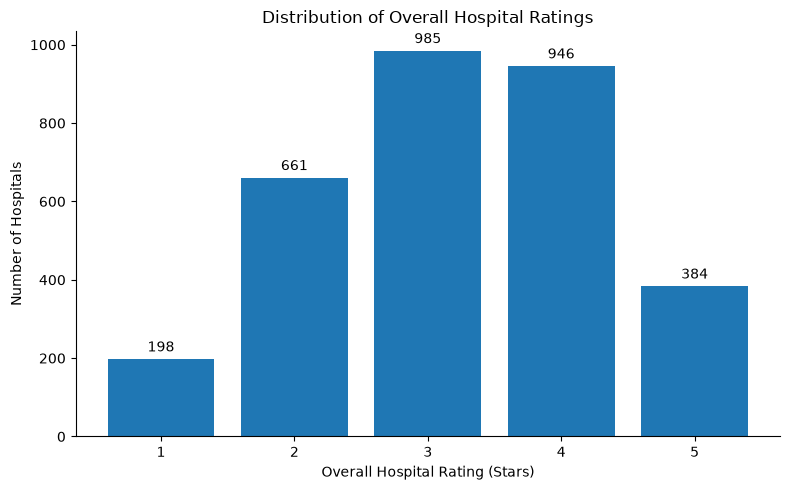

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    rating_counts["overall_rating"],
    rating_counts["hospital_count"]
)

# Add count labels above each bar
ax.bar_label(bars, padding=3)

ax.set_title("Distribution of Overall Hospital Ratings")
ax.set_xlabel("Overall Hospital Rating (Stars)")
ax.set_ylabel("Number of Hospitals")

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "overall_rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 2. Emergency Department Performance by Hospital Rating

**Question:** How does average hospital-level OP_18b performance vary across
overall hospital ratings?

OP_18b measures the median time patients spent in the emergency department
before leaving the ED. Lower values indicate shorter ED stays.

The chart compares the average hospital-level OP_18b median across hospitals
with valid overall ratings and numeric OP_18b scores.

In [6]:
ed_rating_query = """
SELECT
    h.overall_rating,
    COUNT(*) AS hospital_count,
    AVG(hm.score_numeric) AS avg_ed_minutes
FROM hospitals AS h
JOIN hospital_measures AS hm
    ON h.facility_id = hm.facility_id
WHERE hm.measure_id = 'OP_18b'
    AND hm.score_numeric IS NOT NULL
    AND h.overall_rating IN ('1', '2', '3', '4', '5')
GROUP BY h.overall_rating
ORDER BY CAST(h.overall_rating AS INTEGER);
"""

ed_by_rating = pd.read_sql_query(ed_rating_query, conn)

ed_by_rating

,overall_rating,hospital_count,avg_ed_minutes
0,1,187,178.352941
1,2,638,174.111285
2,3,945,173.481481
3,4,877,167.996579
4,5,319,175.087774


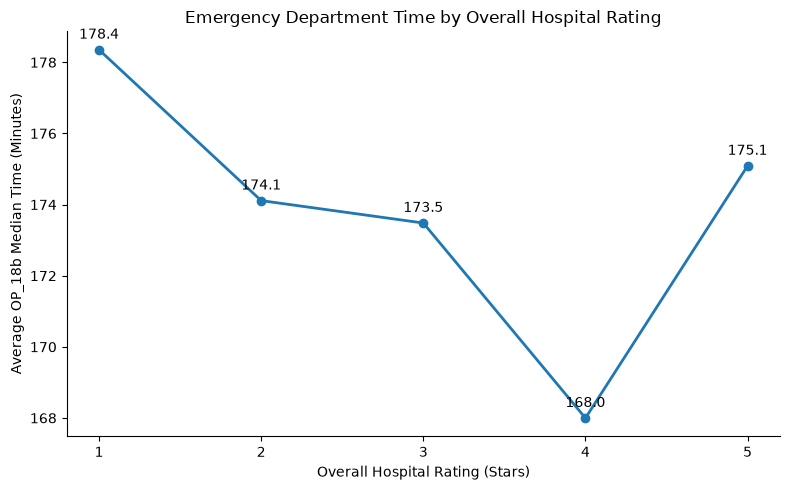

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    ed_by_rating["overall_rating"],
    ed_by_rating["avg_ed_minutes"],
    marker="o",
    linewidth=2
)

# Label each point with its average ED time
for _, row in ed_by_rating.iterrows():
    ax.annotate(
        f'{row["avg_ed_minutes"]:.1f}',
        (row["overall_rating"], row["avg_ed_minutes"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

ax.set_title("Emergency Department Time by Overall Hospital Rating")
ax.set_xlabel("Overall Hospital Rating (Stars)")
ax.set_ylabel("Average OP_18b Median Time (Minutes)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "ed_time_by_hospital_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Washington vs. Other U.S. ED Performance by Hospital Type

**Question:** Does Washington's higher average OP_18b ED time persist when
hospitals are compared within the same hospital type?

Comparing within hospital type helps determine whether the Washington
difference is simply explained by a different mix of hospital types.

In [8]:
wa_type_query = """
SELECT
    h.hospital_type,
    CASE
        WHEN h.state = 'WA' THEN 'Washington'
        ELSE 'Other U.S.'
    END AS region,
    COUNT(*) AS hospital_count,
    AVG(hm.score_numeric) AS avg_ed_minutes
FROM hospitals AS h
JOIN hospital_measures AS hm
    ON h.facility_id = hm.facility_id
WHERE hm.measure_id = 'OP_18b'
    AND hm.score_numeric IS NOT NULL
    AND h.hospital_type IN (
        'Acute Care Hospitals',
        'Critical Access Hospitals'
    )
GROUP BY
    h.hospital_type,
    region
ORDER BY
    h.hospital_type,
    region;
"""

wa_by_type = pd.read_sql_query(wa_type_query, conn)

wa_by_type

,hospital_type,region,hospital_count,avg_ed_minutes
0,Acute Care Hospitals,Other U.S.,2752,175.000727
1,Acute Care Hospitals,Washington,45,194.422222
2,Critical Access Hospitals,Other U.S.,1224,115.932190
3,Critical Access Hospitals,Washington,29,130.379310


In [9]:
wa_type_pivot = wa_by_type.pivot(
    index="hospital_type",
    columns="region",
    values="avg_ed_minutes"
)

wa_type_pivot

region,Other U.S.,Washington
hospital_type,,
Acute Care Hospitals,175.000727,194.422222
Critical Access Hospitals,115.932190,130.379310


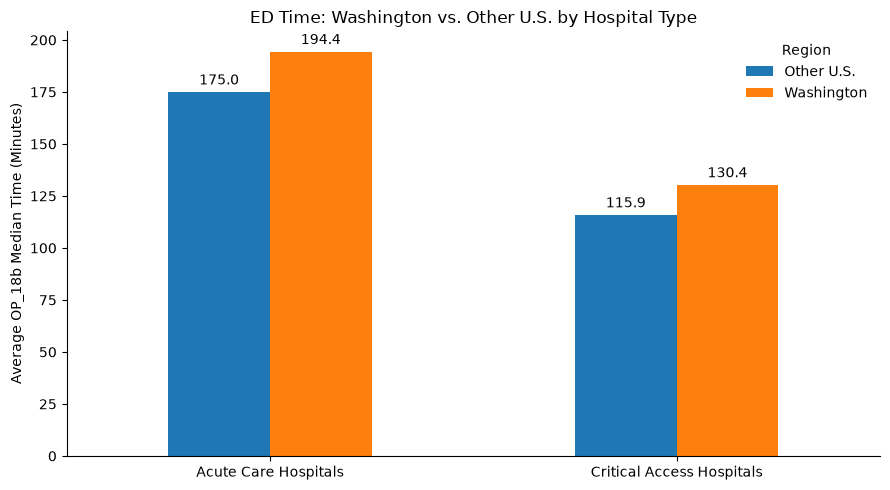

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

wa_type_pivot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("ED Time: Washington vs. Other U.S. by Hospital Type")
ax.set_xlabel("")
ax.set_ylabel("Average OP_18b Median Time (Minutes)")
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Region",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add value labels above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=3
    )

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "wa_vs_us_ed_time_by_hospital_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Washington hospitals have higher average hospital-level OP_18b ED times than
hospitals in the rest of the U.S. within both major hospital types examined.

- Acute Care Hospitals: 194.4 minutes in Washington vs. 175.0 minutes elsewhere
- Critical Access Hospitals: 130.4 minutes in Washington vs. 115.9 minutes elsewhere

Because the difference persists within hospital type, the Washington result
cannot be explained solely by a different mix of Acute Care and Critical
Access hospitals.

However, the Washington sample sizes are much smaller than the comparison
groups, so these results should be interpreted descriptively rather than as
evidence of a causal state-level effect.

## 4. Washington Hospital ED Benchmarking

**Question:** Which Washington hospitals have the shortest and longest
OP_18b ED times relative to hospitals of the same type?

Hospitals are benchmarked within hospital type because Acute Care and
Critical Access hospitals have substantially different OP_18b distributions.
Lower OP_18b values represent shorter median ED stays.

In [11]:
wa_benchmark_query = """
WITH ranked_hospitals AS (
    SELECT
        h.facility_id,
        h.facility_name,
        h.state,
        h.hospital_type,
        hm.score_numeric AS ed_minutes,
        RANK() OVER (
            PARTITION BY h.hospital_type
            ORDER BY hm.score_numeric ASC
        ) AS type_rank,
        COUNT(*) OVER (
            PARTITION BY h.hospital_type
        ) AS type_hospital_count
    FROM hospitals AS h
    JOIN hospital_measures AS hm
        ON h.facility_id = hm.facility_id
    WHERE hm.measure_id = 'OP_18b'
        AND hm.score_numeric IS NOT NULL
        AND h.hospital_type IN (
            'Acute Care Hospitals',
            'Critical Access Hospitals'
        )
)
SELECT *
FROM ranked_hospitals
WHERE state = 'WA'
ORDER BY hospital_type, type_rank;
"""

wa_benchmark = pd.read_sql_query(
    wa_benchmark_query,
    conn
)

wa_benchmark.head(10)

,facility_id,facility_name,state,hospital_type,ed_minutes,type_rank,type_hospital_count
0,500079,MULTICARE GOOD SAMARITAN HOSPITAL,WA,Acute Care Hospitals,133.0,539,2797
1,500002,PROVIDENCE ST MARY MEDICAL CENTER,WA,Acute Care Hospitals,134.0,555,2797
2,500033,SAMARITAN HOSPITAL,WA,Acute Care Hospitals,135.0,581,2797
3,500139,CAPITAL MEDICAL CENTER,WA,Acute Care Hospitals,140.0,685,2797
4,500152,SWEDISH ISSAQUAH,WA,Acute Care Hospitals,141.0,725,2797
5,500016,CONFLUENCE HEALTH HOSPITAL,WA,Acute Care Hospitals,143.0,772,2797
6,500027,SWEDISH MEDICAL CENTER,WA,Acute Care Hospitals,144.0,784,2797
7,500037,ASTRIA TOPPENISH HOSPITAL,WA,Acute Care Hospitals,150.0,926,2797
8,500021,ST CLARE HOSPITAL,WA,Acute Care Hospitals,161.0,1184,2797
9,500036,YAKIMA VALLEY MEMORIAL,WA,Acute Care Hospitals,161.0,1184,2797


In [12]:
wa_benchmark.groupby("hospital_type").agg(
    wa_hospitals=("facility_id", "count"),
    min_ed_minutes=("ed_minutes", "min"),
    median_ed_minutes=("ed_minutes", "median"),
    max_ed_minutes=("ed_minutes", "max")
)

,wa_hospitals,min_ed_minutes,median_ed_minutes,max_ed_minutes
hospital_type,,,,
Acute Care Hospitals,45,133.0,196.0,299.0
Critical Access Hospitals,29,82.0,122.0,202.0


In [13]:
wa_other_type_query = """
SELECT
    h.facility_id,
    h.facility_name,
    h.hospital_type,
    hm.score_numeric AS ed_minutes
FROM hospitals AS h
JOIN hospital_measures AS hm
    ON h.facility_id = hm.facility_id
WHERE h.state = 'WA'
    AND hm.measure_id = 'OP_18b'
    AND hm.score_numeric IS NOT NULL
    AND h.hospital_type NOT IN (
        'Acute Care Hospitals',
        'Critical Access Hospitals'
    );
"""

pd.read_sql_query(wa_other_type_query, conn)

,facility_id,facility_name,hospital_type,ed_minutes
0,50005F,Madigan AMC (FT Lewis),Acute Care - Department of Defense,179.0


In [14]:
wa_benchmark["type_percentile"] = (
    100
    * (
        1
        - (wa_benchmark["type_rank"] - 1)
        / (wa_benchmark["type_hospital_count"] - 1)
    )
)

wa_benchmark[
    [
        "facility_name",
        "hospital_type",
        "ed_minutes",
        "type_rank",
        "type_hospital_count",
        "type_percentile"
    ]
].head(10)

,facility_name,hospital_type,ed_minutes,type_rank,type_hospital_count,type_percentile
0,MULTICARE GOOD SAMARITAN HOSPITAL,Acute Care Hospitals,133.0,539,2797,80.758226
1,PROVIDENCE ST MARY MEDICAL CENTER,Acute Care Hospitals,134.0,555,2797,80.185980
2,SAMARITAN HOSPITAL,Acute Care Hospitals,135.0,581,2797,79.256080
3,CAPITAL MEDICAL CENTER,Acute Care Hospitals,140.0,685,2797,75.536481
4,SWEDISH ISSAQUAH,Acute Care Hospitals,141.0,725,2797,74.105866
5,CONFLUENCE HEALTH HOSPITAL,Acute Care Hospitals,143.0,772,2797,72.424893
6,SWEDISH MEDICAL CENTER,Acute Care Hospitals,144.0,784,2797,71.995708
7,ASTRIA TOPPENISH HOSPITAL,Acute Care Hospitals,150.0,926,2797,66.917024
8,ST CLARE HOSPITAL,Acute Care Hospitals,161.0,1184,2797,57.689557
9,YAKIMA VALLEY MEMORIAL,Acute Care Hospitals,161.0,1184,2797,57.689557


In [15]:
wa_sorted = wa_benchmark.sort_values(
    ["hospital_type", "type_percentile"],
    ascending=[True, False]
)

top3 = (
    wa_sorted
    .groupby("hospital_type", group_keys=False)
    .head(3)
)

bottom3 = (
    wa_sorted
    .groupby("hospital_type", group_keys=False)
    .tail(3)
)

top_bottom = pd.concat(
    [top3, bottom3],
    ignore_index=True
)

top_bottom[
    [
        "facility_name",
        "hospital_type",
        "ed_minutes",
        "type_rank",
        "type_hospital_count",
        "type_percentile"
    ]
].sort_values(
    ["hospital_type", "type_percentile"],
    ascending=[True, False]
)

,facility_name,hospital_type,ed_minutes,type_rank,type_hospital_count,type_percentile
0,MULTICARE GOOD SAMARITAN HOSPITAL,Acute Care Hospitals,133.0,539,2797,80.758226
1,PROVIDENCE ST MARY MEDICAL CENTER,Acute Care Hospitals,134.0,555,2797,80.185980
2,SAMARITAN HOSPITAL,Acute Care Hospitals,135.0,581,2797,79.256080
6,UNIVERSITY OF WASHINGTON MEDICAL CTR,Acute Care Hospitals,266.0,2670,2797,4.542203
7,PEACEHEALTH SOUTHWEST MEDICAL CENTE,Acute Care Hospitals,275.0,2701,2797,3.433476
8,HARBORVIEW MEDICAL CENTER,Acute Care Hospitals,299.0,2742,2797,1.967096
3,GARFIELD COUNTY PUBLIC HOSPITAL DISTRICT #1,Critical Access Hospitals,82.0,89,1253,92.971246
4,ODESSA MEMORIAL HEALTHCARE CENTER,Critical Access Hospitals,95.0,233,1253,81.469649
5,PEACEHEALTH PEACE ISLAND MEDICAL CENTER,Critical Access Hospitals,101.0,331,1253,73.642173
9,ST ELIZABETH HOSPITAL,Critical Access Hospitals,193.0,1241,1253,0.958466


In [16]:
plot_benchmark = (
    top_bottom
    .sort_values("type_percentile")
    .copy()
)

plot_benchmark["type_short"] = (
    plot_benchmark["hospital_type"]
    .replace({
        "Acute Care Hospitals": "ACH",
        "Critical Access Hospitals": "CAH"
    })
)

plot_benchmark["label"] = (
    plot_benchmark["facility_name"]
    + " ("
    + plot_benchmark["type_short"]
    + ")"
)

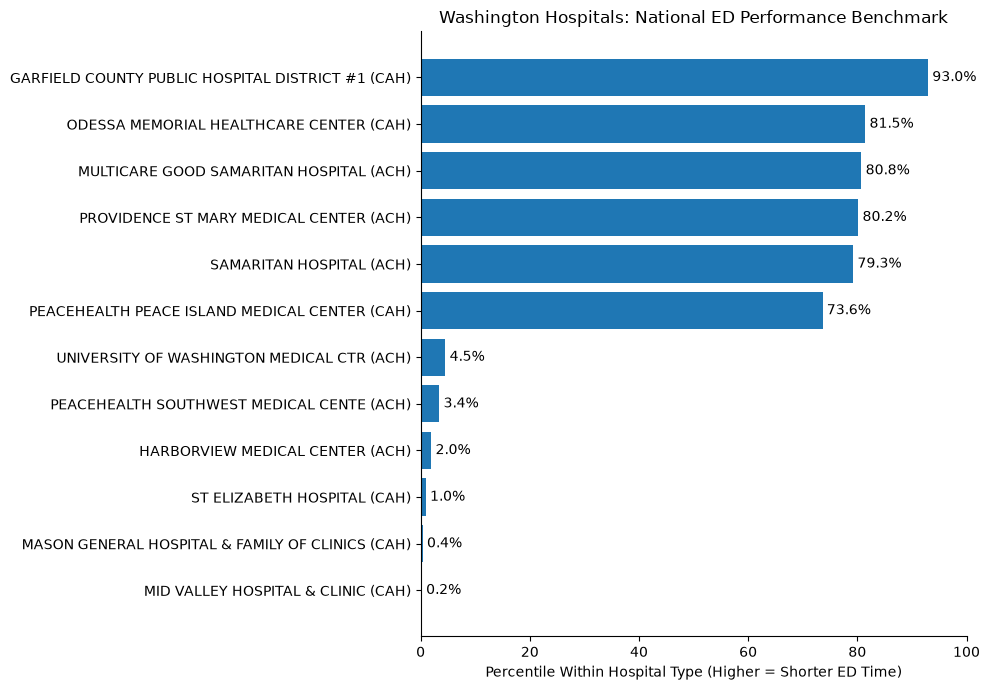

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    plot_benchmark["label"],
    plot_benchmark["type_percentile"]
)

ax.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in plot_benchmark["type_percentile"]
    ],
    padding=3
)

ax.set_title(
    "Washington Hospitals: National ED Performance Benchmark"
)

ax.set_xlabel(
    "Percentile Within Hospital Type (Higher = Shorter ED Time)"
)

ax.set_ylabel("")
ax.set_xlim(0, 100)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "wa_hospital_ed_benchmark.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Washington hospitals show substantial variation in OP_18b performance even
after benchmarking hospitals against others of the same type nationally.

Among the selected extremes, Washington hospitals range from approximately
the 93rd percentile to below the 1st percentile within their respective
hospital types.

The percentile represents relative OP_18b performance within hospital type,
with higher percentiles corresponding to shorter ED times. The figure shows
only the three highest- and three lowest-ranked Washington hospitals within
each of the two major hospital types and therefore should not be interpreted
as the distribution of all Washington hospitals.

ACH = Acute Care Hospital; CAH = Critical Access Hospital.

## Summary of Findings

The visual analysis highlights four findings:

1. **Overall hospital ratings are concentrated in the middle.**
   Among the 3,174 hospitals with numeric ratings, 3-star and 4-star
   hospitals are the most common.

2. **Higher overall ratings do not correspond uniformly to shorter ED times.**
   Average hospital-level OP_18b time decreases from 1-star through 4-star
   hospitals, but increases again among 5-star hospitals. This indicates
   that overall hospital rating and this specific ED measure should not be
   treated as interchangeable measures of quality.

3. **Washington has longer average OP_18b times within both major hospital types.**
   The difference between Washington and the rest of the U.S. persists
   separately among Acute Care and Critical Access hospitals, indicating
   that the statewide difference is not explained solely by hospital-type mix.

4. **Washington hospitals vary substantially in relative ED performance.**
   Within-type national benchmarking shows Washington hospitals at both
   relatively high and very low OP_18b percentiles. State-level averages
   therefore conceal substantial hospital-level variation.

### Limitations

- OP_18b represents one specific dimension of emergency-department performance
  and should not be interpreted as overall hospital quality.
- OP_18b values are hospital-level medians; averages calculated across hospitals
  are not patient-level average ED times.
- Overall hospital ratings are unavailable for a substantial portion of hospitals.
- Washington contains far fewer hospitals than the national comparison group.
- Comparisons are descriptive and do not establish causal relationships.
- Hospital-type benchmarking improves comparability but does not control for
  other differences such as patient population, hospital size, case mix,
  geography, or resource availability.